# Equity H0 peers: coordinates → hierarchy → interpretation → gross comparison

This is the bounded 30-stock pilot approved on October 28, 2026. It compares manual groups, average linkage, single linkage/H0, and a PCA exposure baseline. All performance is **gross/pre-fee**. The data has already been examined; this is exploratory follow-up, not fresh holdout evidence.

Use the **TDA (conda)** kernel. This notebook reads local saved outputs and submits no orders. [Full findings](experiments/equity_h0_peers/README.md), [source](experiments/equity_h0_peers.py), and [project context](../START_HERE.md).

## 1. What is a point?

A point is **one stock**. Its coordinates are its 120 historical daily returns after fitting out SPY, centered and scaled by its own residual volatility. Every stock uses the same dates; every fitting window ends before the signal day. Divide the standardized vector by sqrt(119) to give it unit Euclidean length.

Then two stocks are close if their residual returns moved together over those dates:

`distance(i,j) = sqrt(2 * (1 - correlation(i,j)))`.

This measures normalized comovement, not equal price levels, equal volatility, or mean reversion. It does not preserve temporal ordering: jointly permuting the history dates preserves the distances. We have 30 stock points in 120 time coordinates, not 120 points in 30 stock coordinates.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display
project_candidates = [Path.cwd(), Path.cwd() / "Senior-Fall" / "TDA_Research", *Path.cwd().parents]
project = next(p for p in project_candidates if (p / "START_HERE.md").is_file() and (p / "equity").is_dir())
root = project / "equity"
out = root / "experiments" / "equity_h0_peers"
summary = json.loads((out / "summary.json").read_text())
performance = pd.read_csv(out / "gross_performance_and_structure.csv")
print("Reporting: gross/pre-fee. Models:", summary["configuration"]["models"])
print("Every model has seven independent exposure constraints.")
print("Exploratory on previously examined dates; no novel or profitable TDA advantage established.")

Reporting: gross/pre-fee. Models: ['Manual6', 'Average6', 'Single6', 'H0_6', 'PCA5']
Every model has seven independent exposure constraints.
Exploratory on previously examined dates; no novel or profitable TDA advantage established.


## 2. Can PCA coefficients be coordinates? Yes—with a precise definition

Let the residual correlation matrix be `C = V diag(lambda) V.T`. The stock coordinates `L_ik = V_ik * sqrt(lambda_k)` reproduce C as their Gram matrix. Using **all** these weighted coordinates gives exactly the same distances as the normalized return histories.

Keeping five coordinates intentionally changes the geometry: only the retained component patterns determine distance. On the 2023-12-29 snapshot, the five-coordinate version retained 70% of the three nearest neighbors per stock on average; this does not establish that those neighbors are better.

**Plain eigenvector coefficients without eigenvalue weighting are a trap:** the full orthogonal eigenvector matrix has orthonormal rows, so all stock pairs have distance sqrt(2). Any nearest-neighbor ordering there is numerical tie-breaking, not peer information.

Clustering coordinates also differ from dollar-return factor exposures: for trading constraints we convert back with stock residual volatilities (`diag(sigma) @ V_k`). Column rescaling preserves the exposure span but not arbitrary Euclidean clustering distances.

Appending the full weighted PCA coordinates to their source return histories duplicates the same information and merely rescales all distances by sqrt(2). Appending truncated coordinates emphasizes those directions again. Recent returns are already present; adding only the newest return would add recency weighting and answer a different question. We did not add an extra feature block.

,representation,max_pair_distance_change,relative_pair_distance_error,mean_top3_neighbor_overlap,six_group_ARI_vs_primary
0,Full weighted PCA,0.00000,0.00000,1.00000,1.00000
1,Five weighted PCs,1.04166,0.34572,0.70000,0.56450
2,Full unweighted eigenvectors,0.91864,0.13646,0.04444,-0.06705
3,Original returns (SPY retained),0.36345,0.10793,0.82222,0.62990


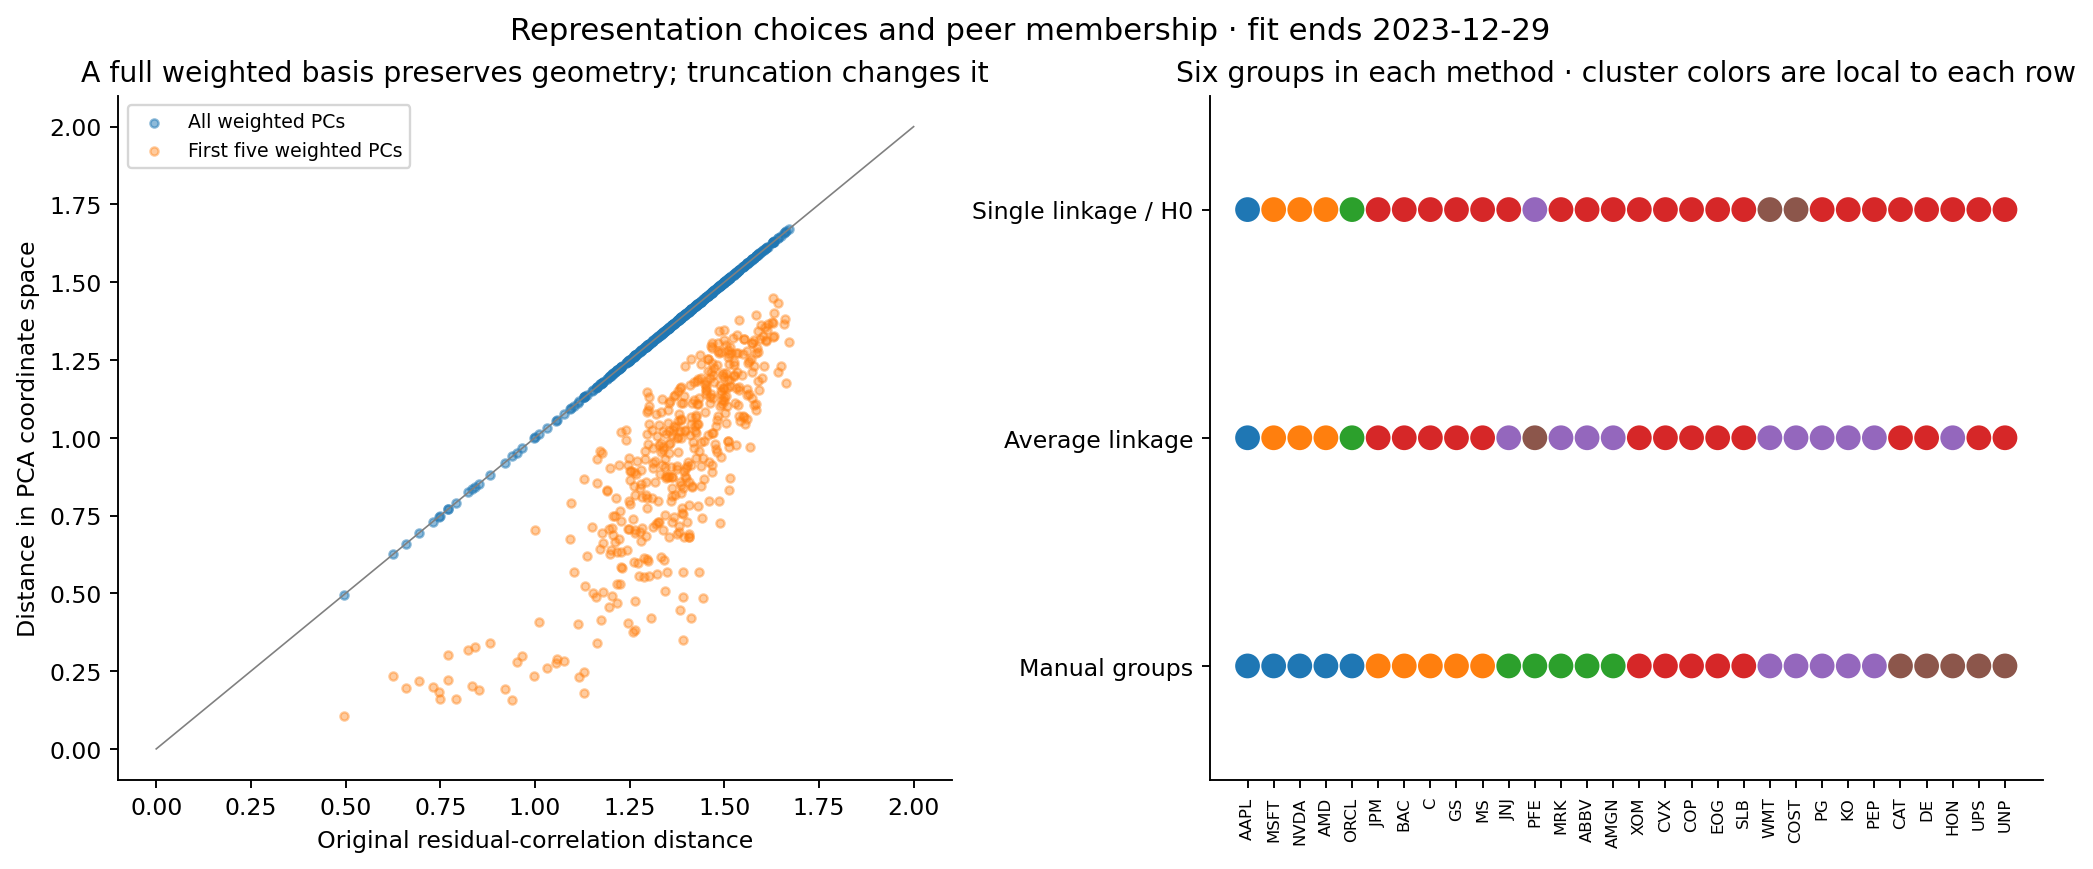

In [2]:
display(pd.read_csv(out / "representation_checks.csv").round(5))
display(Image(filename=str(out / "02_coordinates_and_groups.png")))

## 3. H0: as the distance threshold grows, components merge

At threshold zero, there are 30 isolated stocks. Increase the threshold: pairs within that distance connect, and connected components merge. In an H0 diagram every vertex is born at zero, and finite deaths record component merge distances. One component survives indefinitely.

The left plot retains stock labels and the full merge hierarchy. The right records birth/death distances, without the complete labeled membership structure. Its vertical column is expected because all births are zero. The red line selects six components for this controlled comparison.

This is exactly the **single-linkage** merge process. The implementation independently compares threshold-graph components, SciPy single linkage, minimum-spanning-tree edge weights, and Ripser snapshot H0 diagrams. They agree. A long-lived component can be an isolated stock; persistence does not automatically mean a cohesive group, time stability, significance, or profit.

Checks: {'synthetic_three_groups_recovered': True, 'chain_can_join_distant_endpoints': True, 'unweighted_full_eigenvector_rows_are_equidistant': True, 'stock_return_geometry_equals_correlation_distance': True, 'full_eigenvalue_weighted_coordinates_preserve_distances': True, 'H0_equals_single_linkage_partitions_and_holdings': True, 'MST_deaths_equal_single_linkage_heights': True, 'Ripser_snapshot_deaths_match': True, 'seven_independent_exposures_every_model': True, 'singleton_positions_zero': True}
Maximum H0/single-linkage position difference: 0.0
Maximum scaled exposure error: 6.109439653952536e-14


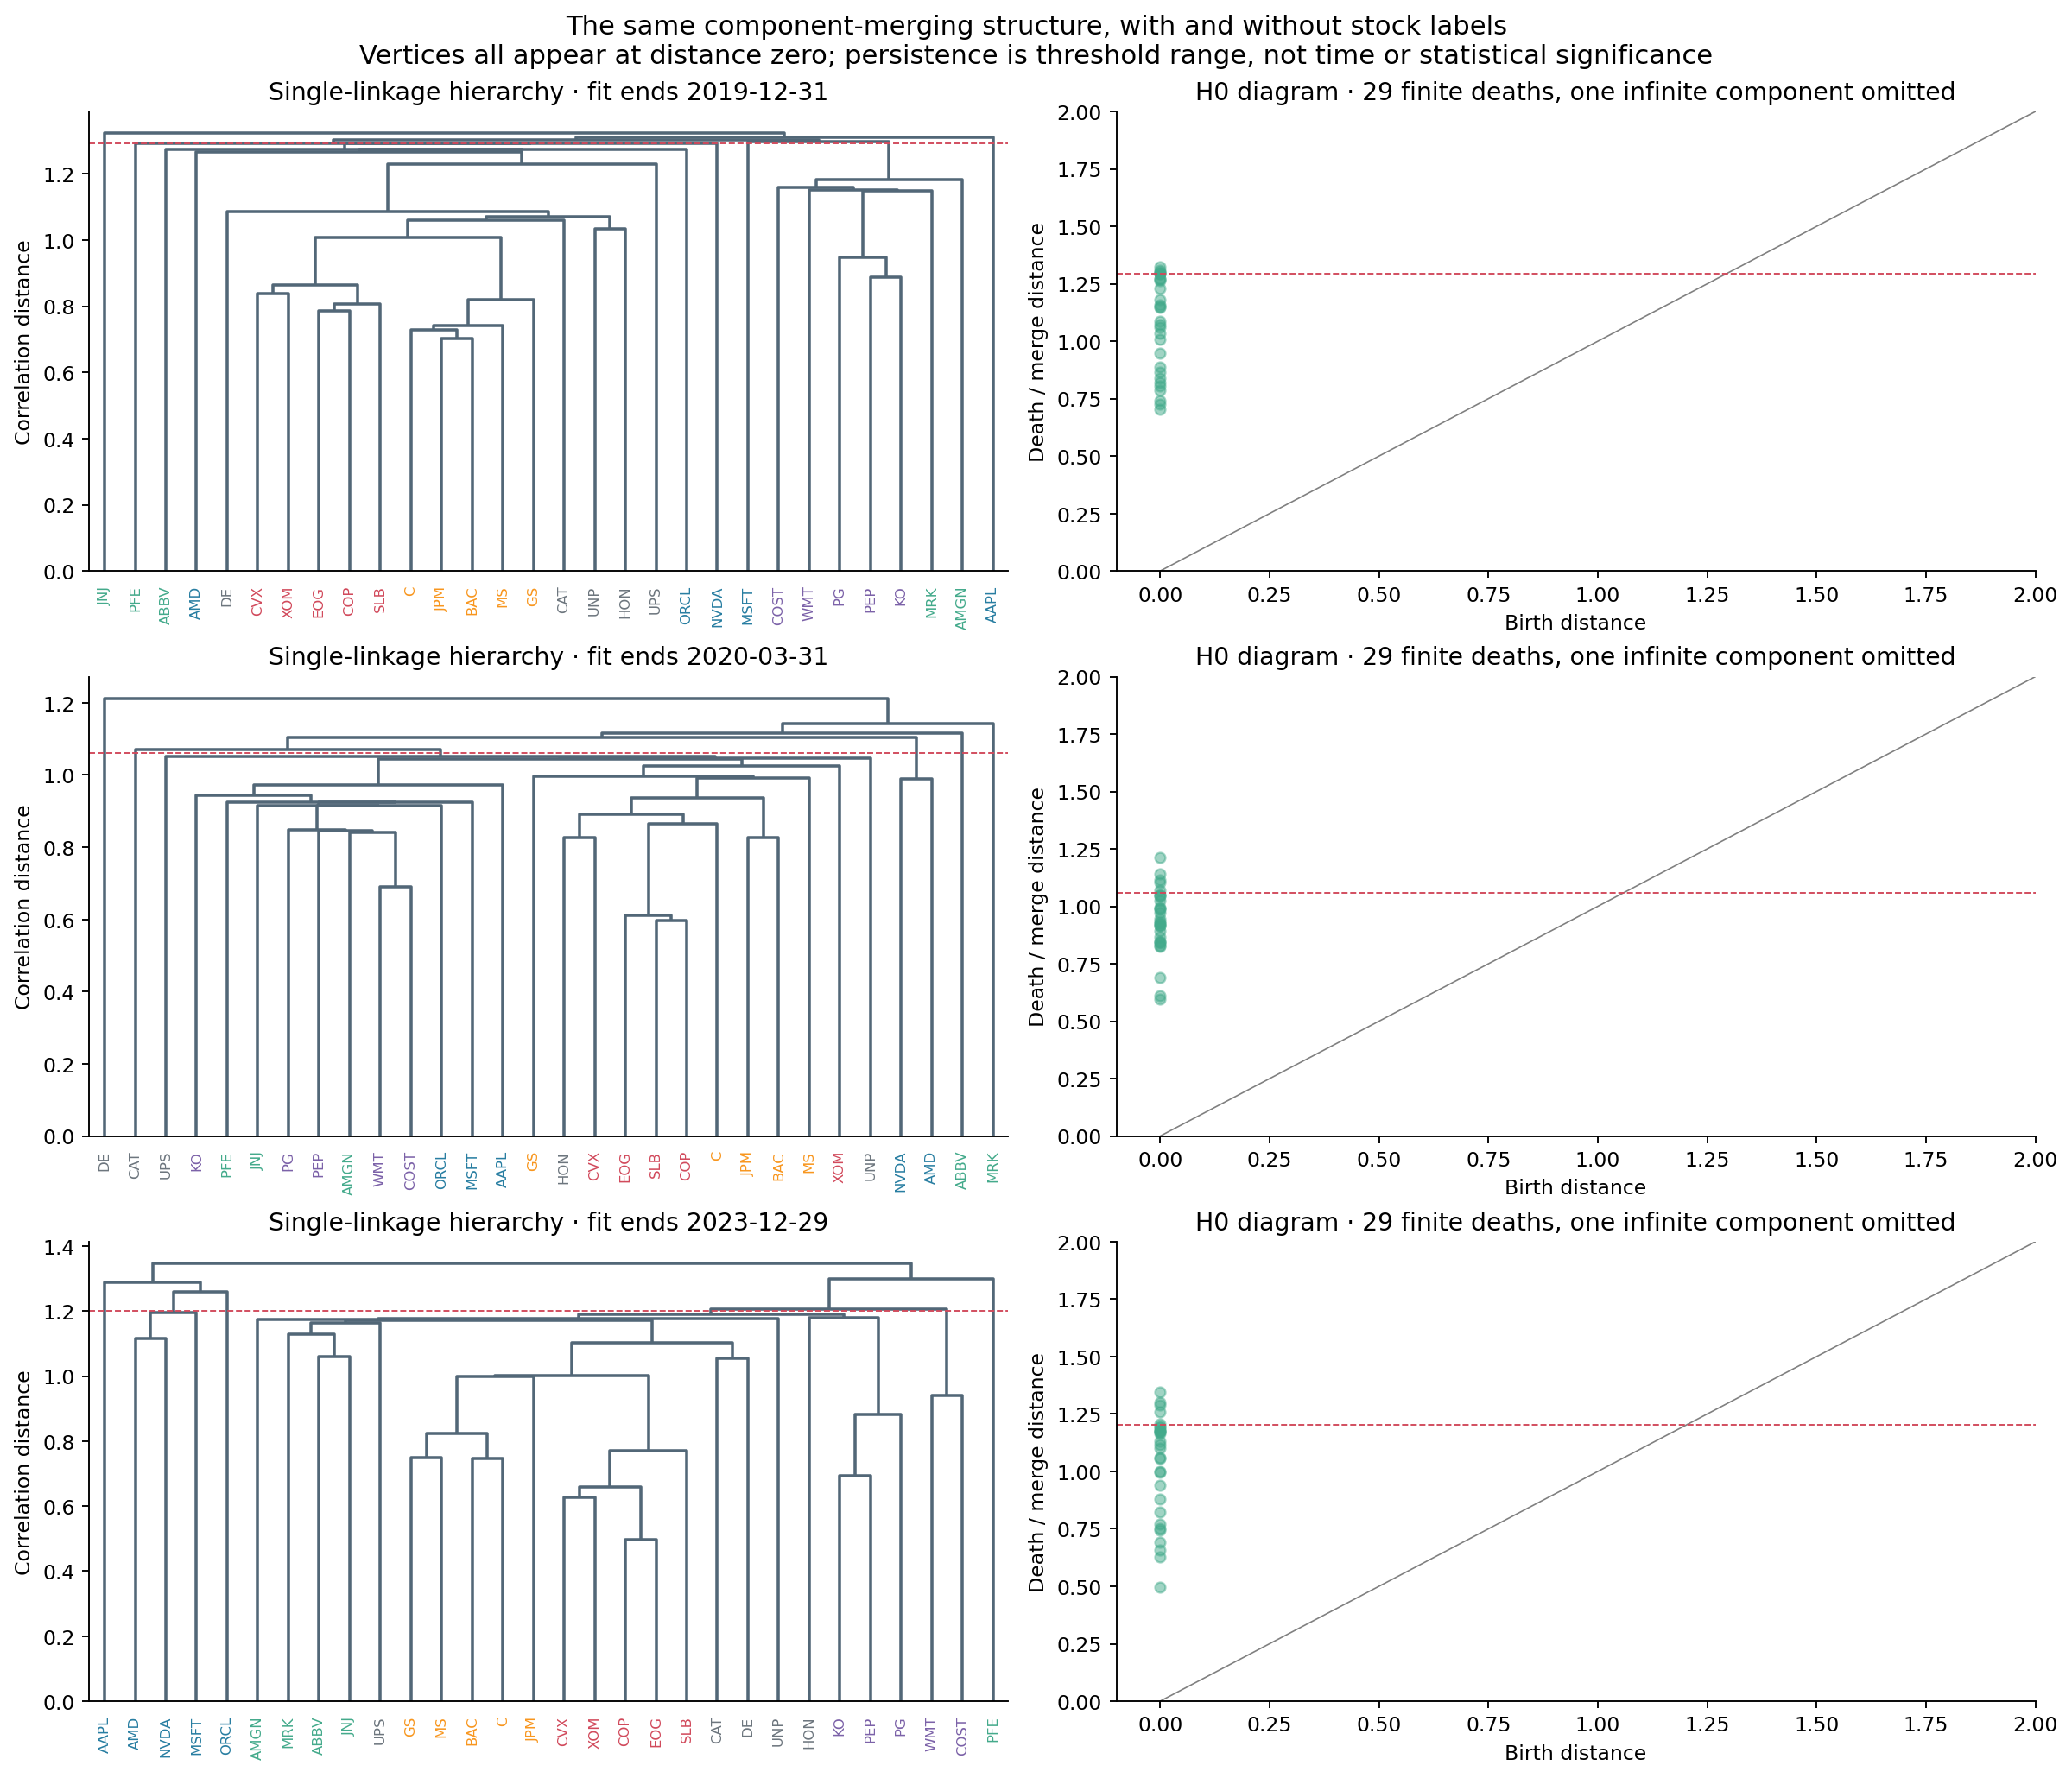

,fit_end,method,cluster,stocks,size
48,2023-12-29,Average6,0,AAPL,1
49,2023-12-29,Average6,1,"MSFT, NVDA, AMD",3
50,2023-12-29,Average6,2,ORCL,1
51,2023-12-29,Average6,3,"JPM, BAC, C, GS, MS, XOM, CVX, COP, EOG, SLB, ...",14
52,2023-12-29,Average6,4,"JNJ, MRK, ABBV, AMGN, WMT, COST, PG, KO, PEP, HON",10
53,2023-12-29,Average6,5,PFE,1
54,2023-12-29,Single6,0,AAPL,1
55,2023-12-29,Single6,1,"MSFT, NVDA, AMD",3
56,2023-12-29,Single6,2,ORCL,1
57,2023-12-29,Single6,3,"JPM, BAC, C, GS, MS, JNJ, MRK, ABBV, AMGN, XOM...",22


In [3]:
display(Image(filename=str(out / "01_labeled_hierarchy_and_H0.png")))
print("Checks:", summary["checks"])
print("Maximum H0/single-linkage position difference:", summary["max_H0_single_holdings_difference"])
print("Maximum scaled exposure error:", summary["max_scaled_exposure_error"])
members = pd.read_csv(out / "snapshot_cluster_members.csv")
display(members.loc[members.fit_end.eq("2023-12-29") & members.method.isin(["Manual6", "Average6", "Single6"])])

## 4. Does six clusters mean six useful local peers?

Not necessarily. Single linkage can connect a long chain of moderately similar neighbors even when its endpoints are far apart. In the later period, its largest group averaged **21.6 of 30 stocks**, alongside **3.21 singleton groups**. The snapshot above has one 22-stock group. Average linkage is less imbalanced here, but also produces singletons.

A singleton group constraint forces that stock's holding to zero; this was checked, not hidden by dropping the stock. Group counts therefore do not establish equal balance, active-stock counts, or diversification.

ARI measures partition agreement despite arbitrary label numbering. One means identical assignments. Day-to-day 120-day windows share 119 observations, so high adjacent agreement is partly expected; fixed manual labels have ARI one by design. A stable giant component is not automatically informative.

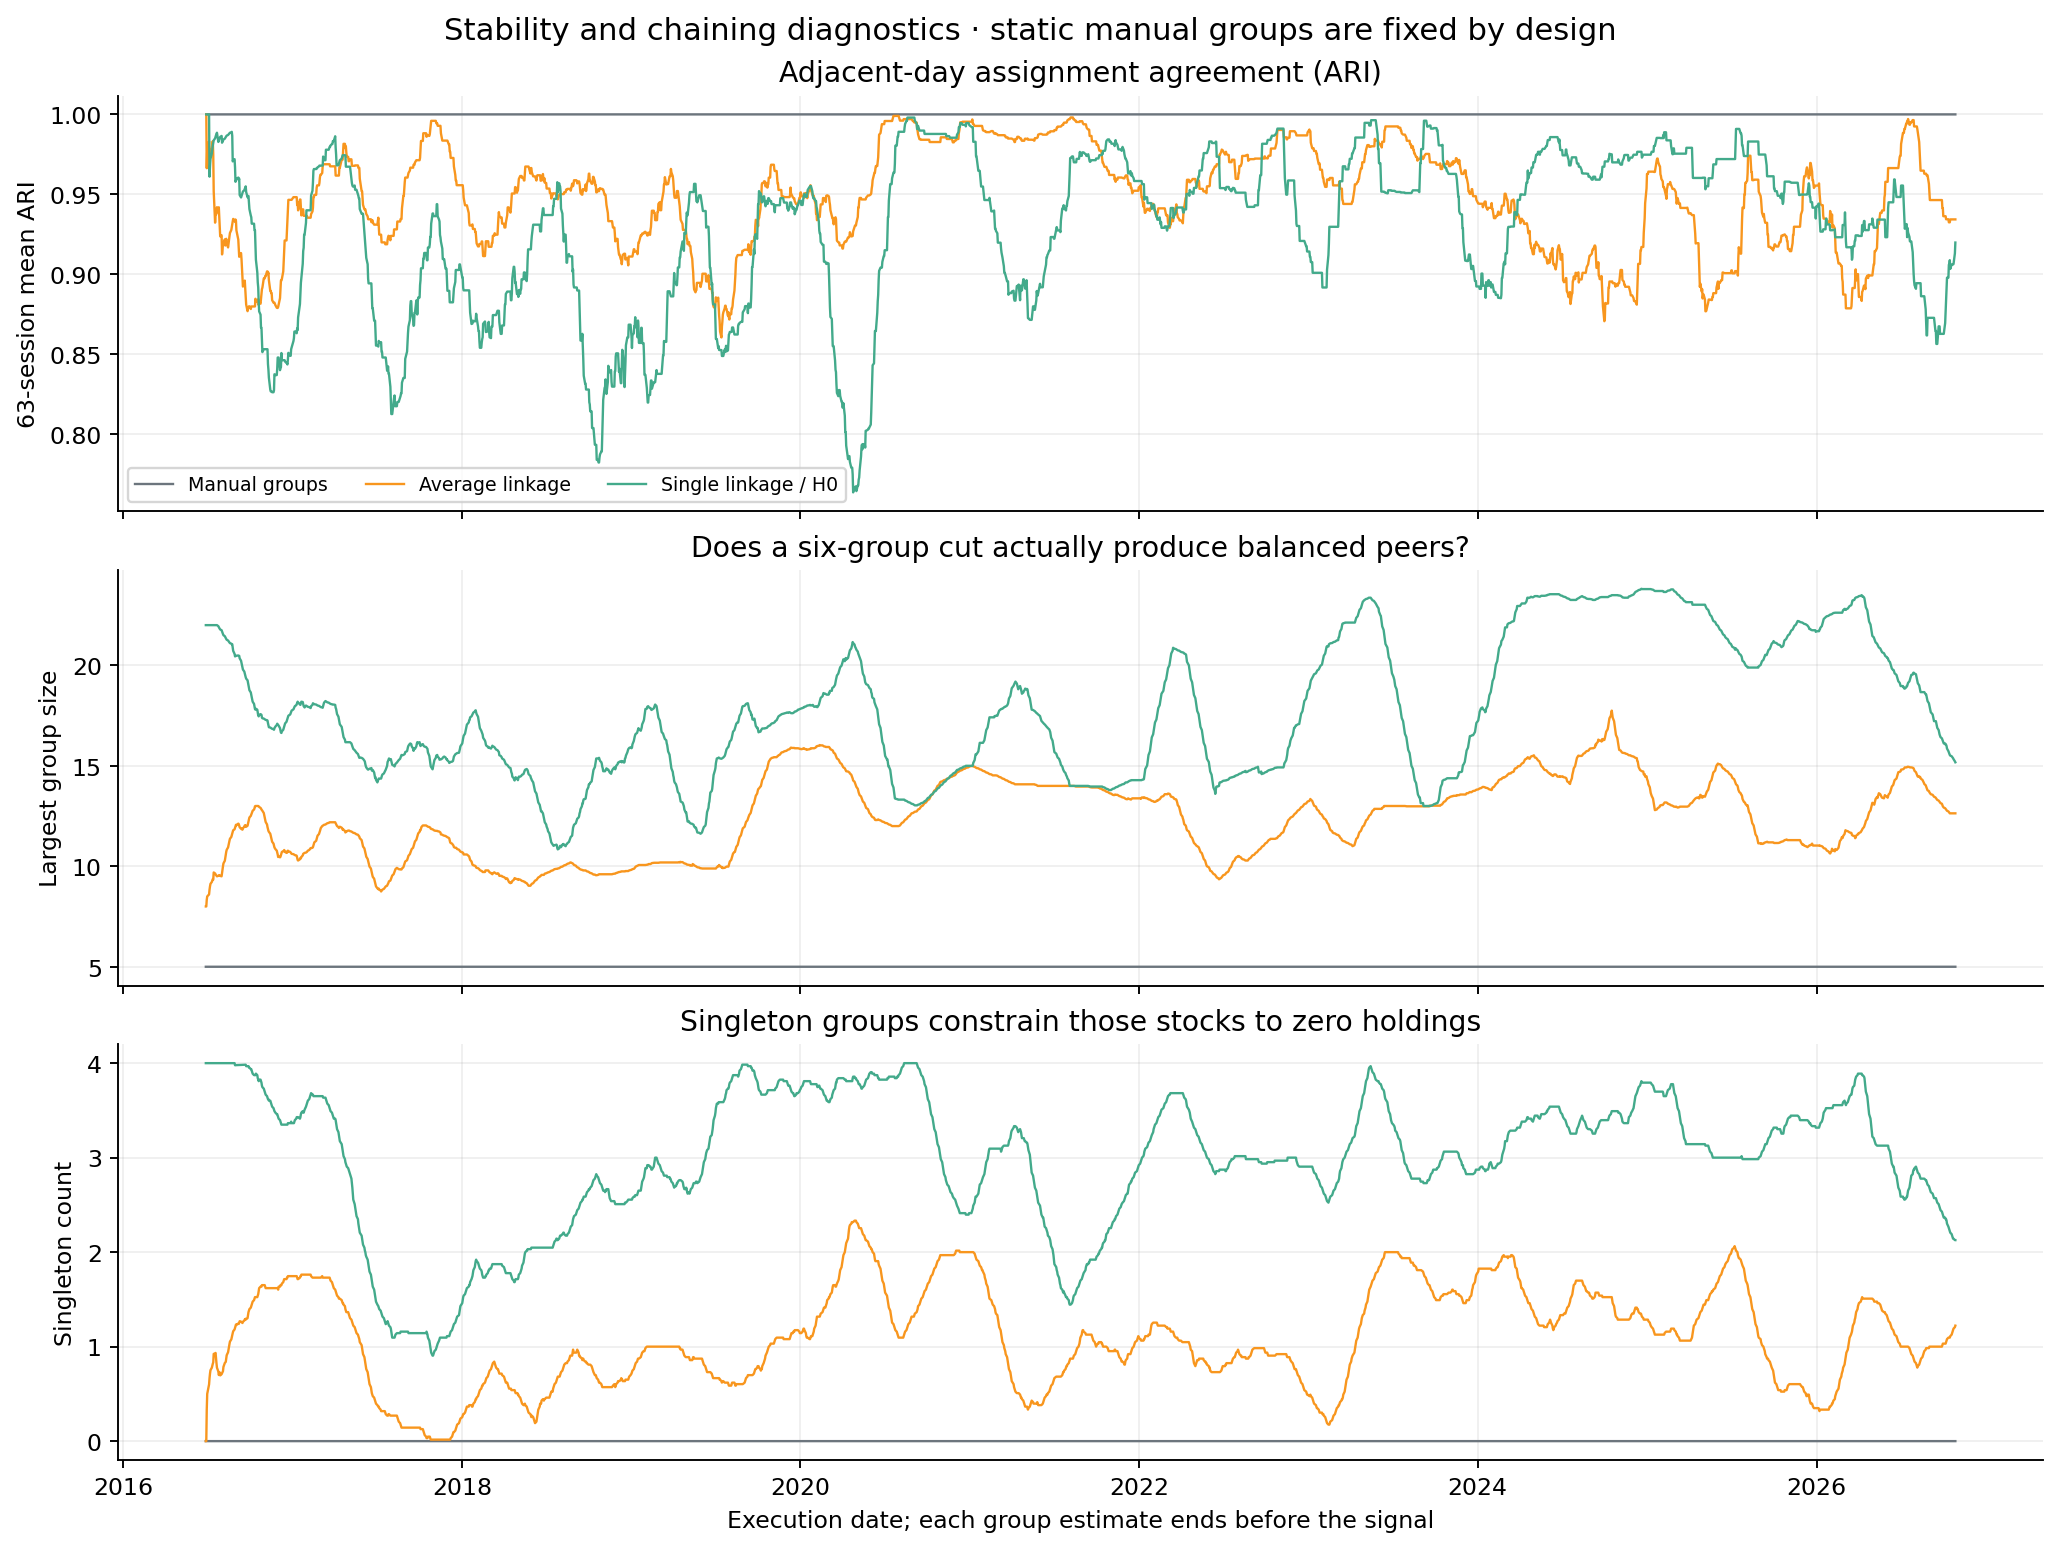

,period,model,mean_largest_group,mean_singletons,mean_adjacent_ARI,mean_active_stocks,mean_effective_breadth
0,development,Average6,12.099,1.056,0.955,28.944,15.532
1,development,H0_6,16.324,2.869,0.921,27.131,14.630
2,development,Manual6,5.000,0.000,1.000,30.000,15.889
4,development,Single6,16.324,2.869,0.921,27.131,14.630
5,evaluation,Average6,13.571,1.222,0.928,28.778,15.277
6,evaluation,H0_6,21.597,3.206,0.951,26.794,14.424
7,evaluation,Manual6,5.000,0.000,1.000,30.000,16.334
9,evaluation,Single6,21.597,3.206,0.951,26.794,14.424


In [4]:
display(Image(filename=str(out / "03_structure_over_time.png")))
display(performance.loc[performance.model.ne("PCA5"), ["period", "model", "mean_largest_group", "mean_singletons", "mean_adjacent_ARI", "mean_active_stocks", "mean_effective_breadth"]].round(3))

## 5. Do groups formed from the past remain coherent afterward?

We assess fixed past-formed groups over 20-session future blocks, with SPY residuals computed using the already estimated betas. Future target blocks do not overlap; blocks crossing the original 2024 boundary are excluded. Prior estimation windows still overlap. There are 94 development blocks and 34 later blocks.

The manual groups have the highest mean future within-minus-between correlation here. That does not establish statistical superiority or economic ground truth: group sizes and within-pair counts differ substantially (60 manual pairs versus about 230 for H0 later). These are descriptive structural measurements, not predicted returns or evidence of a causal sector mechanism.

,period,model,blocks,mean_future_within,mean_future_between,mean_future_peer_gap,mean_within_pairs
0,development,Average6,94,0.3162,-0.0515,0.3677,107.7340
1,development,H0_6,94,0.2210,-0.0575,0.2785,166.0319
2,development,Manual6,94,0.3945,-0.0166,0.4111,60.0000
3,development,Single6,94,0.2210,-0.0575,0.2785,166.0319
4,evaluation,Average6,34,0.2909,-0.0126,0.3035,121.5588
5,evaluation,H0_6,34,0.1948,-0.0650,0.2598,229.6176
6,evaluation,Manual6,34,0.3912,0.0187,0.3725,60.0000
7,evaluation,Single6,34,0.1948,-0.0650,0.2598,229.6176


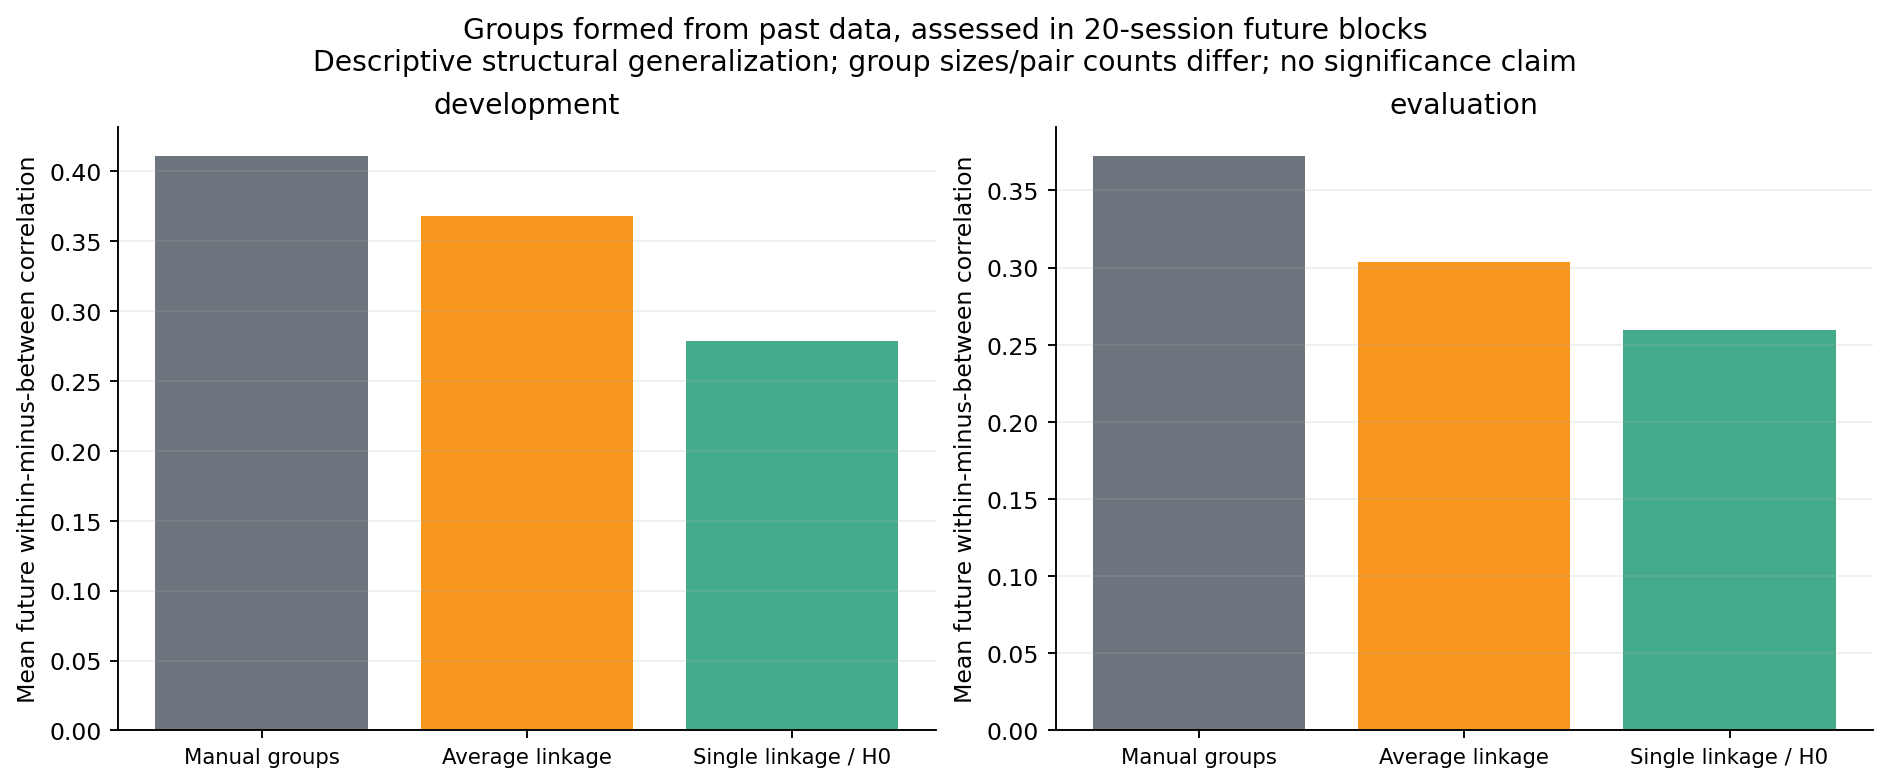

In [5]:
display(pd.read_csv(out / "future_coherence_summary.csv").round(4))
display(Image(filename=str(out / "05_future_peer_coherence.png")))

## 6. Gross strategy comparison with controlled exposure counts

Manual/average/single/H0 use six group indicators plus SPY beta. Complete group indicators already span the intercept. PCA uses five residual-PC exposure columns, SPY beta, and a dollar constraint. Every exposure matrix had rank seven on every date.

All models use the same prior 120-day fits, one-day signal return, inverse-variance WLS construction, 1x gross target, and next vendor-bar raw open-to-close holding. No fees, signal clipping, position caps, or parameter search were added. Vendor fills remain idealized and the fixed selected universe retains survivorship bias.

H0 and single linkage have identical holdings, so the graph draws them once. The later-period manual mean is approximately zero; all alternatives have negative point estimates. The uncertainty intervals are saved. This establishes neither a positive gross edge nor a reliable performance ranking.

,period,model,days,mean_daily_bps,mean_daily_bps_hac95_low,mean_daily_bps_hac95_high,sharpe_vs_zero,compound_annual_growth,mean_active_stocks,max_abs_position
0,development,Average6,1890,0.7522,-0.7668,2.2712,0.3601,0.0177,28.9444,0.3725
1,development,H0_6,1890,0.5365,-1.0870,2.1600,0.2234,0.0118,27.1312,0.4919
2,development,Manual6,1890,0.3930,-0.8999,1.6860,0.2140,0.0089,30.0000,0.3800
3,development,PCA5,1890,0.1778,-1.0935,1.4490,0.0978,0.0034,30.0000,0.3967
4,development,Single6,1890,0.5365,-1.0870,2.1600,0.2234,0.0118,27.1312,0.4919
5,evaluation,Average6,708,-0.5764,-3.3490,2.1962,-0.2587,-0.0160,28.7782,0.3649
6,evaluation,H0_6,708,-0.7551,-3.8894,2.3792,-0.3063,-0.0207,26.7938,0.4034
7,evaluation,Manual6,708,-0.0100,-2.4074,2.3873,-0.0049,-0.0016,30.0000,0.3217
8,evaluation,PCA5,708,-0.7610,-3.0771,1.5552,-0.3973,-0.0201,30.0000,0.3266
9,evaluation,Single6,708,-0.7551,-3.8894,2.3792,-0.3063,-0.0207,26.7938,0.4034


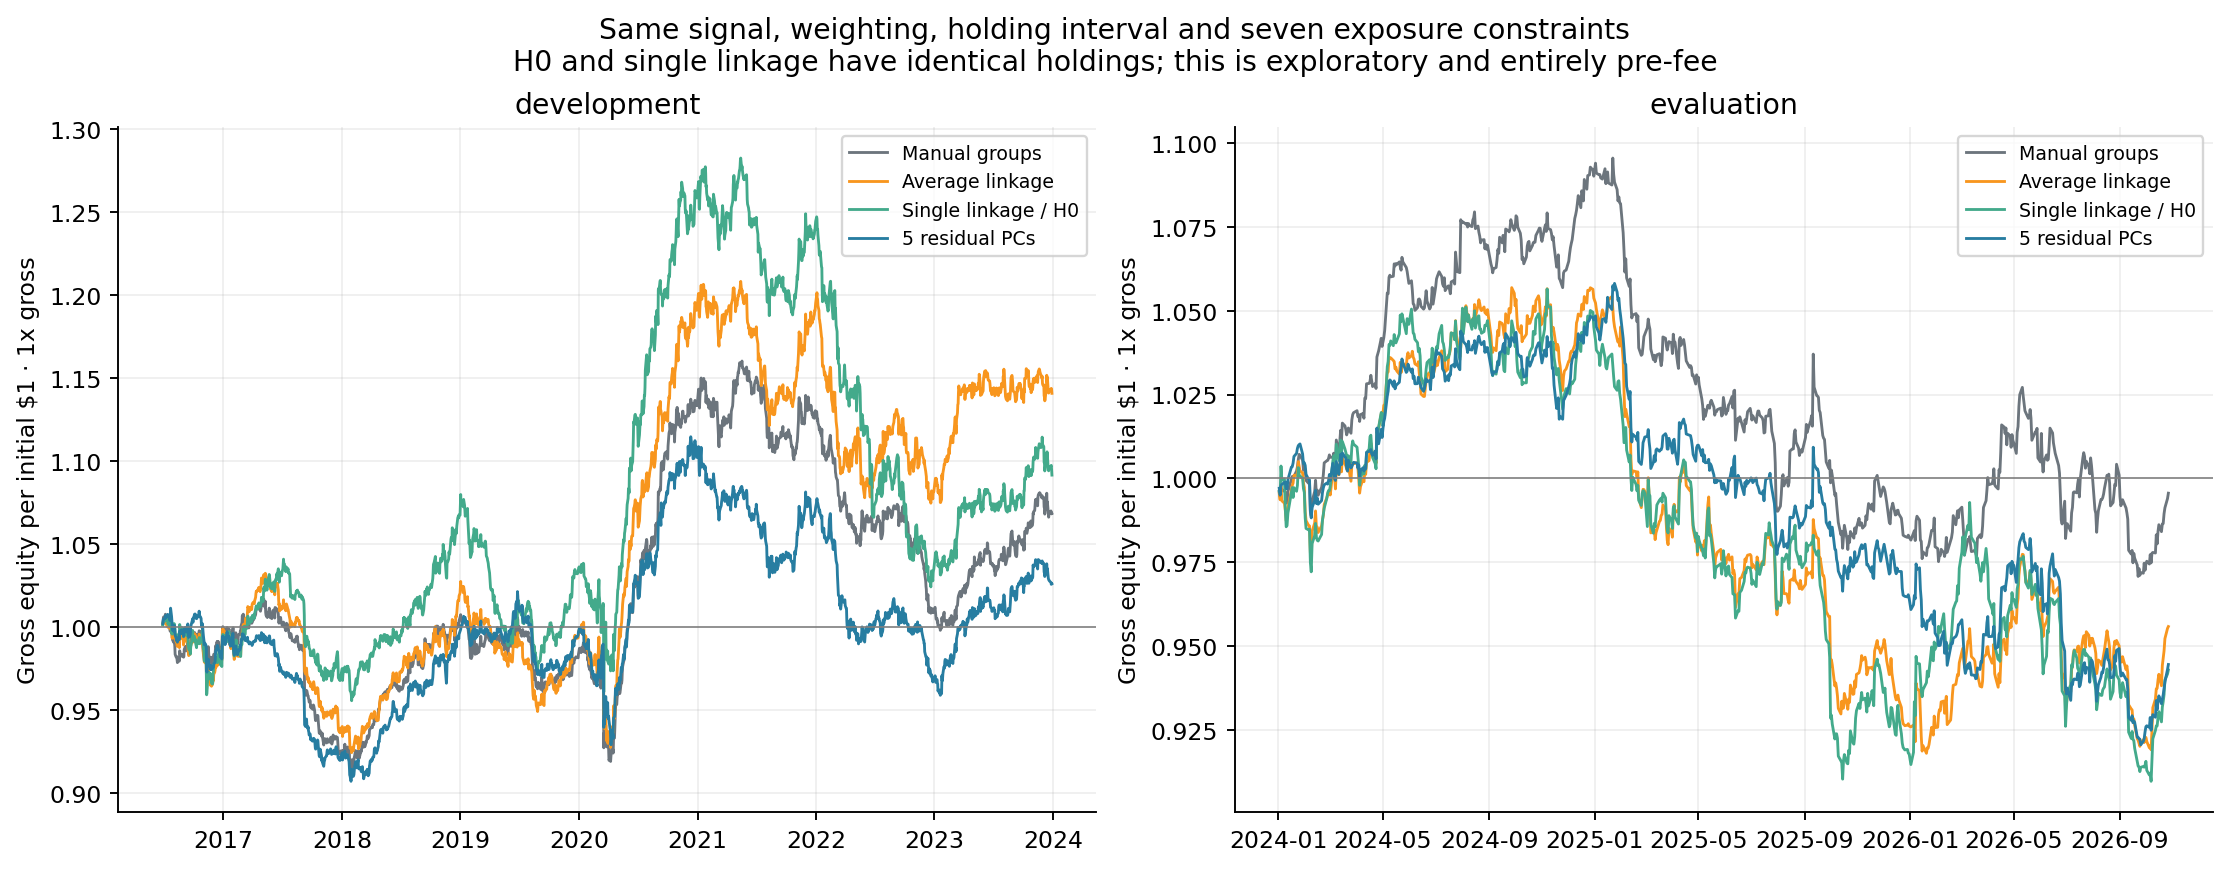

In [6]:
cols = ["period", "model", "days", "mean_daily_bps", "mean_daily_bps_hac95_low", "mean_daily_bps_hac95_high", "sharpe_vs_zero", "compound_annual_growth", "mean_active_stocks", "max_abs_position"]
display(performance[cols].round(4))
display(Image(filename=str(out / "04_gross_peer_comparison.png")))

## What this pilot establishes

We have a reproducible construction linking stock return histories, correctly weighted PCA coordinates, correlation distance, labeled merge hierarchies, and actual H0 diagrams. Its simplest fixed six-component cut exhibits chaining and singleton constraints; it has not improved gross return predictability here.

This is one hierarchy cut. An incremental TDA question still needs an explicitly defined measurement across thresholds or dates, with a simpler comparator. H0 diagrams cannot be treated as a new stock-level factor matrix without defining how labels/exposures are recovered. H1 and extra features were not evaluated. Any next experiment should address a measured limitation rather than assume a more elaborate diagram will repair the signal.

The stock histories are already the input; use the five weighted-PC map only if the intended hypothesis concerns compressed shared exposures, and compare it separately. Adding independent economic data may be reasonable later, but the feature meaning and scaling must be stated first.